In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.io import arff

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (classification_report, confusion_matrix,
                             ConfusionMatrixDisplay, roc_auc_score)

sns.set_theme()
RANDOM_STATE = 42

data, meta = arff.loadarff("../data/Training Dataset.arff")
df = pd.DataFrame(data)
df = df.apply(lambda col: col.str.decode("utf-8") if col.dtype == object else col)
df = df.astype(int)
print("Original shape:", df.shape)

Original shape: (11055, 31)


In [2]:
df = df.drop_duplicates().reset_index(drop=True)
print("After removing duplicates:", df.shape)
print(df["Result"].value_counts())
print(df["Result"].value_counts(normalize=True))

After removing duplicates: (5849, 31)
Result
-1    3019
 1    2830
Name: count, dtype: int64
Result
-1    0.516157
 1    0.483843
Name: proportion, dtype: float64


In [3]:
X = df.drop(columns="Result")
y = df["Result"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)
print("Train:", X_train.shape, "Test:", X_test.shape)
print(y_train.value_counts(normalize=True))
print(y_test.value_counts(normalize=True))

Train: (4679, 30) Test: (1170, 30)
Result
-1    0.516136
 1    0.483864
Name: proportion, dtype: float64
Result
-1    0.516239
 1    0.483761
Name: proportion, dtype: float64


                precision    recall  f1-score   support

 phishing (-1)       0.93      0.90      0.91       604
legitimate (1)       0.90      0.92      0.91       566

      accuracy                           0.91      1170
     macro avg       0.91      0.91      0.91      1170
  weighted avg       0.91      0.91      0.91      1170

ROC-AUC: 0.9737936723375377


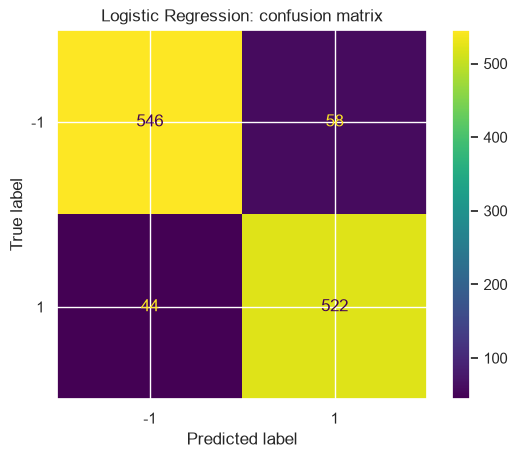

In [4]:
lr = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)
lr.fit(X_train, y_train)
y_pred = lr.predict(X_test)

print(classification_report(y_test, y_pred, target_names=["phishing (-1)", "legitimate (1)"]))
print("ROC-AUC:", roc_auc_score(y_test, lr.predict_proba(X_test)[:, 1]))

ConfusionMatrixDisplay.from_predictions(y_test, y_pred)
plt.title("Logistic Regression: confusion matrix")
plt.savefig("../reports/cm_logreg.png", dpi=150)
plt.show()

## Preprocessing and Baseline Model

### Preprocessing
- **Original data:** 11,055 rows, 31 columns.
- **Duplicates removed:** 5,206 duplicate rows were dropped before splitting to avoid data leakage between the training and test sets. This left **5,849 rows**.
- **Class balance after deduplication:** 3,019 phishing (51.6%) and 2,830 legitimate (48.4%). The classes are now close to balanced, so the majority class has changed compared with the raw data (55.7% legitimate).
- **Train/test split:** 80/20 stratified split with `random_state=42`, giving 4,679 training and 1,170 test samples. Class proportions are preserved in both sets.
- **Scaling:** Not applied, because all features are discrete values in {-1, 0, 1}.

### Baseline: Logistic Regression
| Class | Precision | Recall | F1 | Support |
|---|---|---|---|---|
| Phishing (-1) | 0.93 | 0.90 | 0.91 | 604 |
| Legitimate (1) | 0.90 | 0.92 | 0.91 | 566 |

- **Accuracy:** 0.91
- **ROC-AUC:** 0.974

### Confusion matrix (test set)
| | Predicted phishing | Predicted legitimate |
|---|---|---|
| **Actual phishing** | 546 (TP) | 58 (FN) |
| **Actual legitimate** | 44 (FP) | 522 (TN) |

### Interpretation
- The baseline performs well, with high ROC-AUC, but it is not perfect.
- **False negatives (58, about 9.6% of phishing sites)** are the most serious error: a phishing site is treated as safe and a user could be harmed.
- **False positives (44, about 7.8% of legitimate sites)** block safe sites, which costs user trust and productivity.
- Scores are lower than those often reported on the raw, duplicated dataset, which supports the decision to remove duplicates first.
- Next steps: compare tree-based models, tune hyperparameters with cross-validation, and examine the threshold trade-off between false negatives and false positives.